In [1]:
import os, sys, mne, socket, time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from nilearn import plotting

from initialization import load_paths
from preprocFuncs import getRawData, getTrials, getPower
from plotters import plotPower, plotRSA

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
subjID = 99
day = 3
p = load_paths(subjID, day)
# Load behavioral data
master_df = pd.read_csv(os.path.join(p['meta'], 'master_df.csv'))
behav_df = master_df[(master_df['subjID'] == subjID) & (master_df['day'] == 1)]
relevCols = [col for col in behav_df.columns if 'oriArray_' not in col]
behav_df = behav_df[relevCols]
# Load raw data
raw_data = getRawData(p)

# Define events
events, tah = mne.events_from_annotations(raw_data)
events_dict = {
    'BlockOnset': 1001,
    'BlockEnd': 7,
    'Fixation': 1,
    'Delay1': 2,
    'Delay2': 3,
    'Response': 4,
    'Feedback': 5,
    'ITI': 6,
}
trl_events = {
    'inPF': 11,
    'outPF': 10,
}

# Define electrodes of interest
left_occ_elecs = ['O1', 'PO3', 'PO7', 'P1', 'P3', 'P7']
right_occ_elecs = ['O2', 'PO4', 'PO8', 'P2', 'P4', 'P8']

# trials_list = getTrials(raw_data, events_dict, events)

Running pre-processing ...
Extracting parameters from /d/DATD/datd/TMS_ori/EEGfiles/sub99/day03/sub99_day03.vhdr...
Setting channel info structure...
Reading 0 ... 4382679  =      0.000 ...  4382.679 secs...
Used Annotations descriptions: ['Response/R  1', 'Stimulus/S  1', 'Stimulus/S  2', 'Stimulus/S  3', 'Stimulus/S  4', 'Stimulus/S  5', 'Stimulus/S  6', 'Stimulus/S  7', 'Stimulus/S 10', 'Stimulus/S 11']


In [3]:
epochData = mne.Epochs(raw_data, events, event_id=trl_events, tmin=-2, tmax=2.5, baseline=None, preload=True)
inPF_trials = behav_df[behav_df['stimPF'] == 0].index
outPF_trials = behav_df[behav_df['stimPF'] == 1].index

Not setting metadata
312 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 312 events and 4501 original time points ...
0 bad epochs dropped


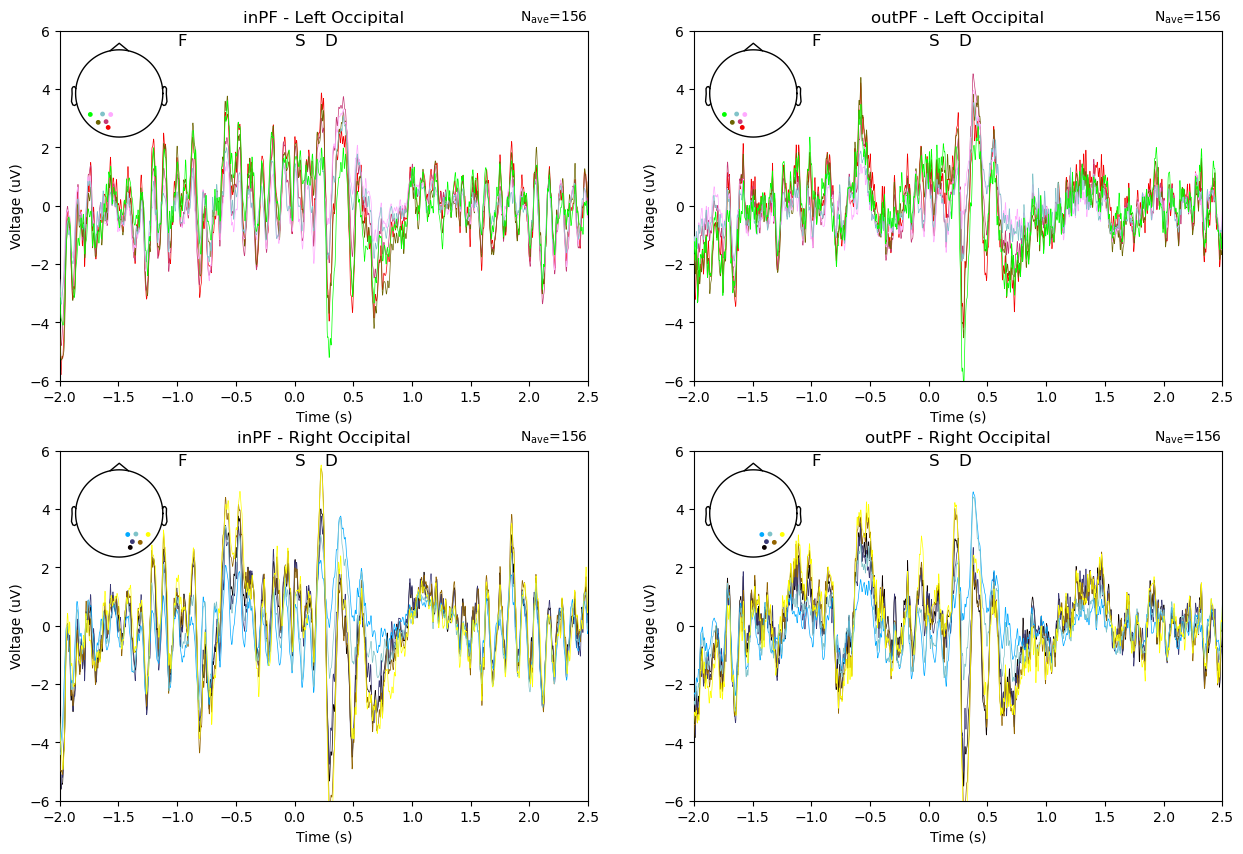

In [16]:
evokedinPF = epochData[inPF_trials].average()
evokedoutPF = epochData[outPF_trials].average()
f, axs = plt.subplots(2, 2, figsize=(15, 10))
axs= axs.flatten()
evokedinPF.plot(picks=left_occ_elecs, show=False, axes=axs[0])
evokedoutPF.plot(picks=left_occ_elecs, show=False, axes=axs[1])
evokedinPF.plot(picks=right_occ_elecs, show=False, axes=axs[2])
evokedoutPF.plot(picks=right_occ_elecs, show=False, axes=axs[3])
for ax in axs:
    ax.set_ylim(-6, 6)
    ax.set_ylabel('Voltage (uV)')
    ax.set_xlabel('Time (s)')
    ax.text(-1, 5.5, 'F', fontsize=12, color='black')
    ax.text(0, 5.5, 'S', fontsize=12, color='black')
    ax.text(0.25, 5.5, 'D', fontsize=12, color='black')

# axs[0].text(0, -4, 'F', fontsize=12, color='black')
axs[0].set_title('inPF - Left Occipital')
axs[1].set_title('outPF - Left Occipital')
axs[2].set_title('inPF - Right Occipital')
axs[3].set_title('outPF - Right Occipital')
plt.show()

Effective window size : 2.048 (s)
Effective window size : 2.048 (s)
Averaging across epochs...
Averaging across epochs...
Averaging across epochs...
Averaging across epochs...


/var/folders/cf/d9j3_ppd5wb4bn9y_fgj3nb800010l/T/ipykernel_3993/1686268632.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


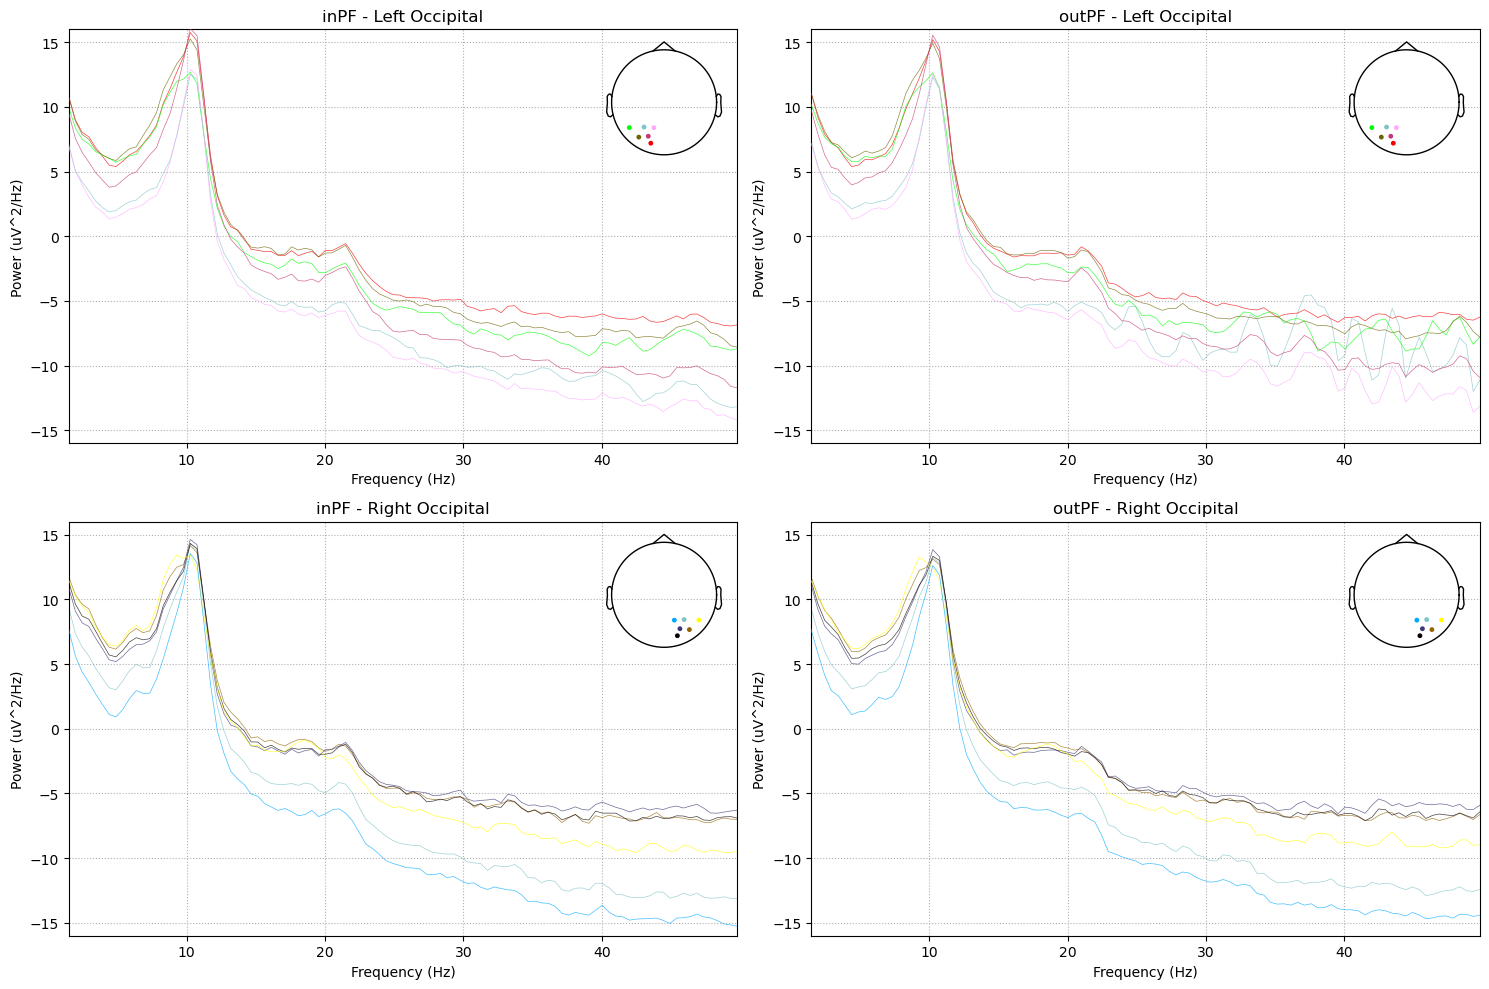

In [28]:
# Compute PSD for each condition
psd_inPF = epochData[inPF_trials].compute_psd(fmin=1, fmax=50, method='welch', n_fft=2048, n_overlap=1024)
psd_outPF = epochData[outPF_trials].compute_psd(fmin=1, fmax=50, method='welch', n_fft=2048, n_overlap=1024)

f, axs = plt.subplots(2, 2, figsize=(15, 10))
axs = axs.flatten()

psd_inPF.plot(picks=left_occ_elecs, show=False, axes=axs[0])
axs[0].set_title('inPF - Left Occipital')

psd_outPF.plot(picks=left_occ_elecs, show=False, axes=axs[1])
axs[1].set_title('outPF - Left Occipital')

psd_inPF.plot(picks=right_occ_elecs, show=False, axes=axs[2])
axs[2].set_title('inPF - Right Occipital')

psd_outPF.plot(picks=right_occ_elecs, show=False, axes=axs[3])
axs[3].set_title('outPF - Right Occipital')

# Customize the plots
for ax in axs:
    ax.set_ylabel('Power (uV^2/Hz)')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylim(-16, 16)  

plt.tight_layout()
plt.show()

In [85]:
# Plot topomap for band power
band_to_plot = 'broadband'
if band_to_plot == 'alpha':
    l_freq, h_freq = 8, 12
elif band_to_plot == 'beta':
    l_freq, h_freq = 15, 25
elif band_to_plot == 'theta':
    l_freq, h_freq = 4, 7
elif band_to_plot == 'broadband':
    l_freq, h_freq = 1, 50

rawDataNew = raw_data.copy()
rawDataNew = mne.add_reference_channels(rawDataNew, ref_channels='Cz')
rawDataNew = rawDataNew.set_eeg_reference(ref_channels='average')
epochDataBaseCorr = mne.Epochs(rawDataNew, events, event_id=trl_events, tmin=-2, tmax=2.5, baseline=None, preload=True)

powerInPF = epochDataBaseCorr[inPF_trials].copy().filter(l_freq=l_freq, h_freq=h_freq, n_jobs=4)
powerOutPF = epochDataBaseCorr[outPF_trials].copy().filter(l_freq=l_freq, h_freq=h_freq, n_jobs=4)

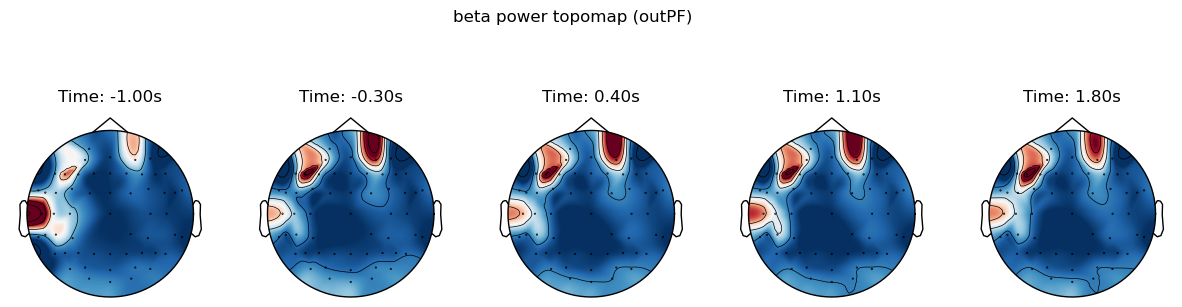

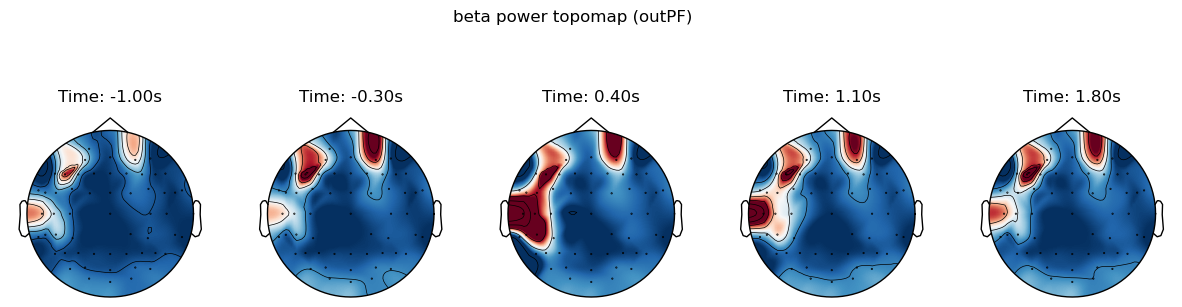

In [83]:
times_to_plot = np.linspace(-1, 2.5, 6)
qtl_thresh = 0.01

# Figure for inPF condition
fig, axs = plt.subplots(1, len(times_to_plot)-1, figsize=(15, 4))
axs = axs.flatten()
for i, time in enumerate(times_to_plot[:-1]):
    idx_start = powerInPF.time_as_index(time)
    idx_end = powerInPF.time_as_index(times_to_plot[i+1]) 
    idx_start = idx_start[0]
    idx_end = idx_end[0] 
    
    avg_powerInPF = np.mean(np.abs(powerInPF.get_data(copy=True)[:, :, idx_start:idx_end])**2, axis=(0,-1)) 
    avg_powerOutPF = np.mean(np.abs(powerOutPF.get_data(copy=True)[:, :, idx_start:idx_end])**2, axis=(0,-1))

    low_qtl = np.quantile(avg_powerInPF, qtl_thresh)
    high_qtl = np.quantile(avg_powerInPF, 1-qtl_thresh)
    
    mne.viz.plot_topomap(avg_powerInPF, powerInPF.info, axes=axs[i], show=False, cmap='RdBu_r', vlim=(low_qtl, high_qtl))
    axs[i].set_title(f'Time: {time:.2f}s')

plt.suptitle(f'{band_to_plot} power topomap (outPF)', fontsize=12)
plt.show()

# Figure for outPF condition
fig, axs = plt.subplots(1, len(times_to_plot)-1, figsize=(15, 4))
axs = axs.flatten()
for i, time in enumerate(times_to_plot[:-1]):
    idx_start = powerOutPF.time_as_index(time)
    idx_end = powerOutPF.time_as_index(times_to_plot[i+1]) 
    idx_start = idx_start[0]
    idx_end = idx_end[0] 
    
    avg_powerInPF = np.mean(np.abs(powerInPF.get_data(copy=True)[:, :, idx_start:idx_end])**2, axis=(0,-1)) 
    avg_powerOutPF = np.mean(np.abs(powerOutPF.get_data(copy=True)[:, :, idx_start:idx_end])**2, axis=(0,-1))

    low_qtl = np.quantile(avg_powerInPF, qtl_thresh)
    high_qtl = np.quantile(avg_powerInPF, 1-qtl_thresh)
    
    mne.viz.plot_topomap(avg_powerOutPF, powerOutPF.info, axes=axs[i], show=False, cmap='RdBu_r', vlim=(low_qtl, high_qtl))
    axs[i].set_title(f'Time: {time:.2f}s')

plt.suptitle(f'{band_to_plot} power topomap (outPF)', fontsize=12)
plt.show()

In [ ]:
window_size = 0.5
overlap = 0.1
freq_band = 'alpha'
bandPower, twindow_power = getPower(trials_list, window_size, overlap, freq_band)
   

In [ ]:
plt.figure()
plt.hist(bandPower.flatten(), bins=100)
plt.show()

In [ ]:
# leftTrials = trials_list[trials_list['instimPF'] == 1]
inPF_trials = behav_df[behav_df['stimPF'] == 0].index 
outPF_trials = behav_df[behav_df['stimPF'] == 1].index
# leftbandPower = bandPower[leftTrials, :, :]
ch_names = trials_list[0].ch_names
sfreq = trials_list[0].info['sfreq']
# Plot a topo plot of the power
info = mne.create_info(ch_names, sfreq, ch_types='eeg')
montage = trials_list[0].get_montage()
info.set_montage(montage)

data_window = np.mean(bandPower[inPF_trials, :, :], axis=(0,))
# bandPower_corrected = data_window.copy()

baseline_time = np.where((twindow_power[0] >= 1) & (twindow_power[0] < 2))[0]
baseline_ = data_window[:, baseline_time]
baseline_average = np.mean(baseline_, axis=(1))
baseline_average = np.expand_dims(baseline_average, axis=(1))
# baseline_average = np.expand_dims(baseline_average, axis=2)
bandPower_corrected = (data_window - baseline_average) / baseline_average
bandPower_corrected = data_window / baseline_average
qt_thresh = 0.01
qt_low = np.quantile(bandPower_corrected, qt_thresh)
qt_high = np.quantile(bandPower_corrected, 1-qt_thresh)
evoked = mne.EvokedArray(bandPower_corrected, info)
# evoked = mne.EvokedArray(data_window[:, np.newaxis], info)
times = np.linspace(1, 6, 10)
evoked.plot_topomap(times=times, show=True, time_unit='s', scalings=1, time_format='%.2f', cmap='RdBu_r',
                    image_interp='nearest', ch_type='eeg', colorbar=True, res=120, vlim=(qt_low, qt_high))
plt.show()


In [ ]:
plt.figure()
plt.hist(bandPower_corrected.flatten(), bins=100)
plt.show()

In [ ]:
leftOccElecsIdx = [trials_list[0].ch_names.index(ch) for ch in left_occ_elecs]
rightOccElecsIdx = [trials_list[0].ch_names.index(ch) for ch in right_occ_elecs]
leftOccBandPower = bandPower[:, leftOccElecsIdx, :]
rightOccBandPower = bandPower[:, rightOccElecsIdx, :]

# leftPower = left_occ_alpha_power.copy()
# rightPower = right_occ_alpha_power.copy()

# left_occ_alpha_power = (leftPower-rightPower) / (leftPower+rightPower+1e-10)
# right_occ_alpha_power = (rightPower-leftPower) / (rightPower+leftPower+1e-10)

# # left_occ_alpha_power = (left_occ_alpha_power - right_occ_alpha_power) / (left_occ_alpha_power + right_occ_alpha_power + 1e-10)
# # right_occ_alpha_power = (right_occ_alpha_power - left_occ_alpha_power) / (right_occ_alpha_power + left_occ_alpha_power + 1e-10)
baseline_time = np.where((twindow_power[0] > 1) & (twindow_power[0] < 2))
baseline_average = (np.mean(leftOccBandPower[:, :, baseline_time]) + np.mean(rightOccBandPower[:, :, baseline_time])) / 2

# left_occ_alpha_power /= baseline_average
# right_occ_alpha_power /= baseline_average

leftOccBandPower = (leftOccBandPower - baseline_average) / baseline_average
rightOccBandPower = (rightOccBandPower - baseline_average) / baseline_average

conds_power = 'byOri'
plotPower(leftOccBandPower, rightOccBandPower, twindow_power, behav_df, freq_band, conds_power)

In [ ]:
conds_RSA = 'byPF'
plotRSA(bandPower, twindow_power, behav_df, conds_RSA, leftOccElecsIdx, rightOccElecsIdx)

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(10, 10))
all_occ_elecs = left_occ_elecs + right_occ_elecs
for channel in range(len(all_occ_elecs)):
    # Find this channel in trials_list.info['ch_names']
    ch_idx = trials_list[50].info['ch_names'].index(all_occ_elecs[channel])
    axs[0].plot(twindow_power[0], alpha_power[0][ch_idx])
    axs[1].plot(twindow_power[1], alpha_power[1][ch_idx])
plt.show()

In [ ]:
trial_data = trials_list[50]
# Plot ERP with topoplot
# evoked = trial_data.average()
# trial_data.plot_topomap(times=[0.1, 0.2, 0.3, 0.4, 0.5], time_unit='s', ch_type='eeg', title='ERP', show=False)
# trial_data.plot_psd(fmin=0, fmax=50, average=True, spatial_colors=False, show=False)
trial_data.plot_psd_topomap(ch_type='eeg', normalize=True, show=True)
plt.show()

In [ ]:
f, axs = plt.subplots(1, 2, figsize=(10, 5))
trl_ = 1
axs[0].plot(trials_list[trl_].times, trials_list[trl_].get_data()[0])
# axs[1].plot(trials_list[trl_].times, alpha_power[trl_])
axs[1].plot(twindow_power[trl_], alpha_power[trl_])
plt.show()

In [ ]:
raw_data.compute_psd(fmax=55, average='mean', n_fft=2048).plot()
plt.show()

In [ ]:
raw_data = mne.add_reference_channels(raw_data, ref_channels='Cz')

In [ ]:
# Plot ERP across all trials do it manually
plt.figure()

mean_data = np.mean([trial.get_data() for trial in trials_list], axis=0)
plt.plot(trials_list[0].times, mean_data[0, 0, :])
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (uV)')
plt.title('ERP across all trials')
plt.show()

In [ ]:
block.info['sfreq']

In [ ]:
# Get variance of electrodes across whole recording
elec_var = raw_data.get_data().var(axis=1)

In [ ]:
# Plot data for block 0 for selected time window
block_epochs_list[0].plot(n_channels=64, scalings=dict(eeg=20e-5), title='Block 0')
plt.show()

In [ ]:
# Print duration of the epochs
total_dur = 0
for epoch in epochs_list:
    total_dur += epoch.times[-1]
    print(f'Epoch duration: {epoch.times[-1]:.2f} s')
print(f'Total duration: {total_dur:.2f} s')

In [ ]:
# Re-epoch data